# 04 · Baseline models

Three baselines: **Logistic Regression**, **Decision Tree**, **Random Forest**, scored on accuracy, precision, recall, F1 and ROC-AUC.

**Recall comes first.** A missed case (sick patient told they're fine) costs far more than a false alarm (healthy patient sent for more tests).

Setup (all in `src/modeling.py`):
- Features: the 22 one-hot encoded columns from `heart_encoded.csv`. Target: `target` (1 = disease).
- **Split:** stratified 75/25 → 222 training / 75 test patients.
- **Model comparison:** 5-fold cross-validation on the training set only.
- **Final numbers:** the test set, used once.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src import plots
from src.modeling import (
    BEST_MODEL, METRICS, TARGET_RECALL, evaluate, forest_permutation_importance,
    logistic_coefficients, prepare_data, threshold_table,
)

plots.apply_style()
FIG_DIR = Path.cwd().parent / "reports" / "figures"

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

X, y = prepare_data()
results = evaluate(X, y)
print(f"{X.shape[1]} features, {len(y)} patients, test set: {len(results.y_test)} ({results.y_test.sum()} with disease)")

22 features, 297 patients, test set: 75 (35 with disease)


## 1. Cross-validation (training set)

Mean of 5 folds, ± standard deviation. This is the fairer comparison: five estimates instead of one.

In [2]:
cv = pd.DataFrame({
    plots.METRIC_LABELS[m]: results.cv[f"{m}_mean"].map("{:.3f}".format) + " ± " + results.cv[f"{m}_std"].map("{:.3f}".format)
    for m in METRICS
})
cv

,Accuracy,Precision,Recall,F1,ROC-AUC
model,,,,,
Logistic Regression,0.824 ± 0.043,0.819 ± 0.039,0.792 ± 0.104,0.802 ± 0.060,0.880 ± 0.046
Decision Tree,0.784 ± 0.051,0.779 ± 0.095,0.755 ± 0.032,0.764 ± 0.048,0.857 ± 0.032
Random Forest,0.815 ± 0.049,0.814 ± 0.045,0.772 ± 0.110,0.789 ± 0.070,0.920 ± 0.039


## 2. Held-out test set

Each model trained on all 222 training patients, scored once on the 75 test patients with the default 0.5 threshold.

In [3]:
results.test.round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.853,0.853,0.829,0.841,0.937
Decision Tree,0.733,0.727,0.686,0.706,0.782
Random Forest,0.840,0.871,0.771,0.818,0.924


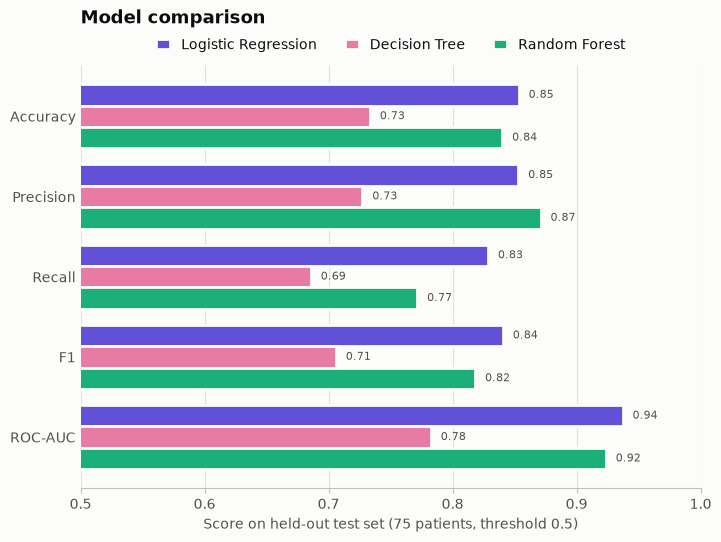

In [4]:
fig = plots.model_comparison(results.test)
save(fig, "06_model_comparison")
plt.show()

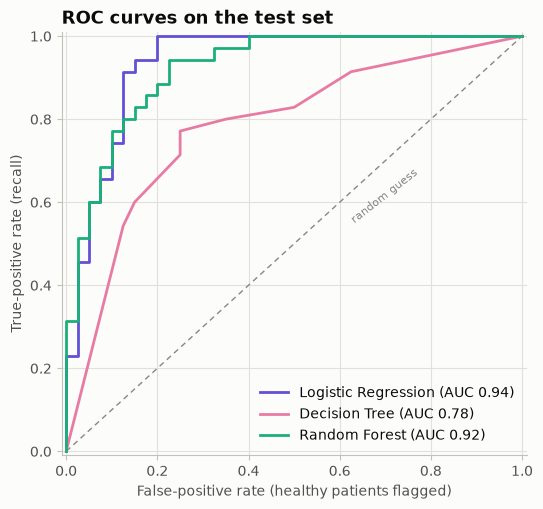

In [5]:
fig = plots.roc_curves(results.roc, results.test["roc_auc"])
save(fig, "07_roc_curves")
plt.show()

## 3. Tuning for recall

Logistic Regression is the strongest model in cross-validation (accuracy, recall, F1) and on the test set. A probability of 0.5 is an arbitrary cut-off. For screening it makes sense to flag a patient at a lower probability.

The threshold is chosen **on the training set only** (out-of-fold predictions): the highest cut-off that still catches at least 90% of the sick patients there. Then it's checked once on the test set.

In [6]:
print(f"Recall-focused threshold: {results.threshold}")
pd.DataFrame({"threshold 0.5": results.test.loc[BEST_MODEL],
              f"threshold {results.threshold}": pd.Series(results.test_at_threshold)}).round(3)

Recall-focused threshold: 0.19


,threshold 0.5,threshold 0.19
accuracy,0.853,0.853
precision,0.853,0.761
recall,0.829,1.000
f1,0.841,0.864
roc_auc,0.937,0.937


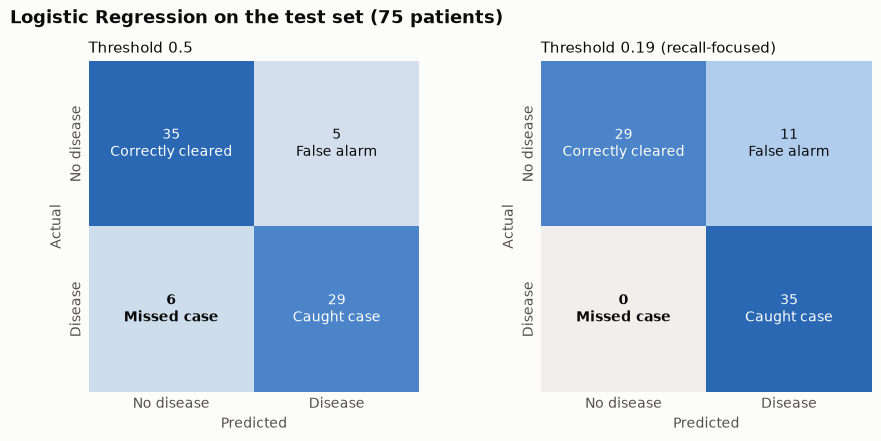

In [7]:
from sklearn.metrics import confusion_matrix
prob = results.test_probs[BEST_MODEL]
fig = plots.confusion_matrices({
    "Threshold 0.5": results.confusion[BEST_MODEL],
    f"Threshold {results.threshold} (recall-focused)": confusion_matrix(results.y_test, (prob >= results.threshold).astype(int)),
})
fig.suptitle("Logistic Regression on the test set (75 patients)", x=0.01, ha="left", y=1.04, fontweight="bold", fontsize=13)
save(fig, "08_confusion_matrices")
plt.show()

The full trade-off on the test set. Lowering the threshold catches more cases at the cost of more false alarms:

In [8]:
threshold_table(results.y_test, prob).round(2)

,threshold,recall,precision,missed_cases,false_alarms
0,0.10,1.00,0.70,0,15
1,0.15,1.00,0.76,0,11
2,0.20,1.00,0.78,0,10
3,0.25,1.00,0.81,0,8
4,0.30,0.94,0.80,2,8
5,0.35,0.94,0.82,2,7
6,0.40,0.91,0.86,3,5
7,0.45,0.86,0.86,5,5
8,0.50,0.83,0.85,6,5
9,0.55,0.80,0.85,7,5


## 4. Feature importance

Two views:
- **Logistic Regression coefficients.** Features are standardised, so each bar is the effect of a one-standard-deviation increase. The sign shows direction.
- **Random Forest permutation importance.** How much test ROC-AUC drops when one feature is shuffled. It shows what the model relies on, but not the direction.

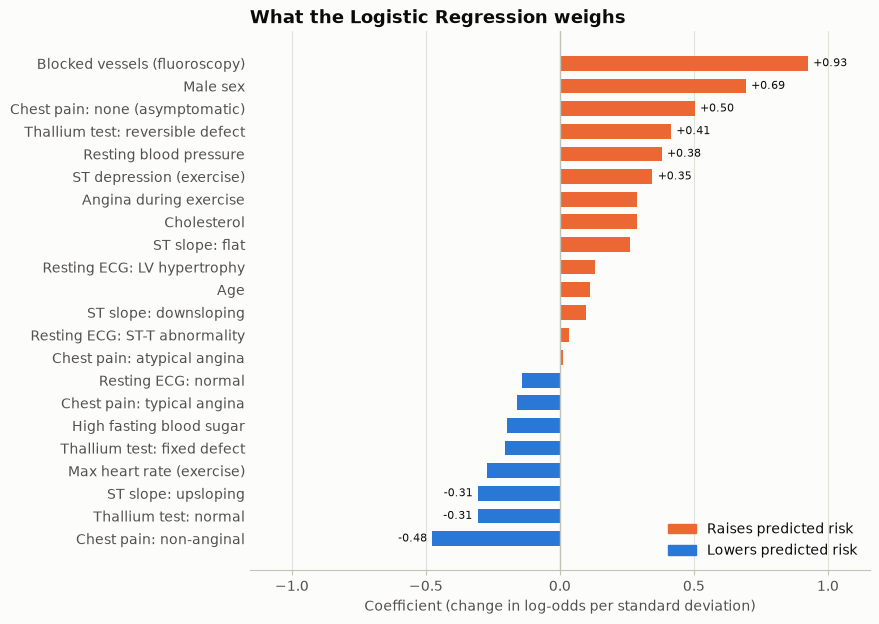

In [9]:
coefs = logistic_coefficients(results, X.columns)
fig = plots.logistic_coefficients(coefs)
save(fig, "09_logistic_coefficients")
plt.show()

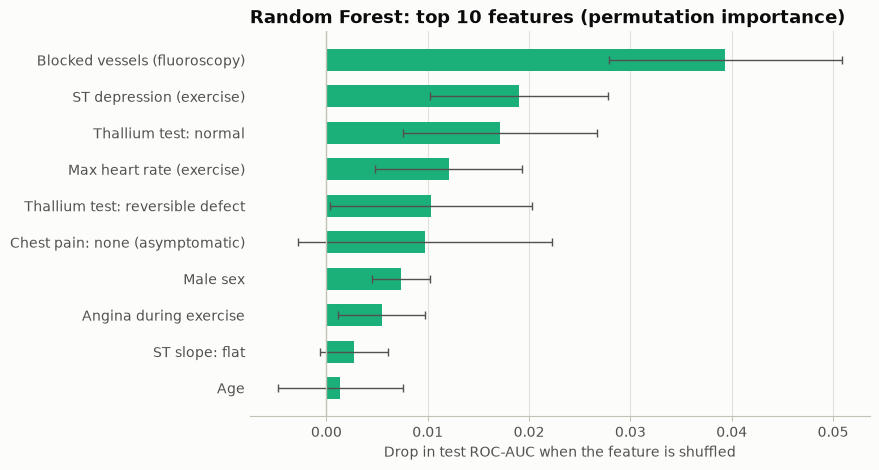

In [10]:
imp = forest_permutation_importance(results, X, y)
fig = plots.permutation_importance_chart(imp)
save(fig, "10_forest_importance")
plt.show()

In [11]:
pd.DataFrame({
    "LR coefficient": coefs.reindex(imp.index[:10]).round(2),
    "RF importance": imp["importance"].head(10).round(3),
})

,LR coefficient,RF importance
ca,0.93,0.039
oldpeak,0.35,0.019
thal_normal,-0.31,0.017
thalach,-0.27,0.012
thal_reversible_defect,0.41,0.010
cp_asymptomatic,0.50,0.010
sex,0.69,0.007
exang,0.29,0.005
slope_flat,0.26,0.003
age,0.11,0.001


## 5. Results and top factors in plain language

**Results**
- **Logistic Regression is the best baseline.** It has the highest cross-validated accuracy, recall and F1, and on the test set: accuracy 0.85, recall 0.83, ROC-AUC 0.94. The Random Forest comes close (ROC-AUC 0.92). The single Decision Tree trails (0.78).
- **With a recall-focused threshold (0.19)**, it caught **all 35** sick patients in the test set. The cost: 11 of 40 healthy patients flagged for follow-up instead of 5. With only 35 cases, a perfect score is partly luck. Cross-validation on the training data targeted about 90% recall, which is the more realistic expectation.

**Top factors.** Both models agree on the top signals:
1. **Blocked vessels on fluoroscopy.** The more major vessels that show narrowing on the X-ray dye test, the more likely the patient has disease. This is the strongest factor in both models.
2. **Exercise stress test results.** A low max heart rate, ST depression (a dip in the ECG trace during exercise) and chest pain brought on by exercise all point to a heart that struggles under load.
3. **Thallium scan.** A normal scan lowers the predicted risk. A *reversible defect*, where blood flow drops during exercise and recovers at rest, raises it.
4. **No chest pain ("asymptomatic").** Counter-intuitively, patients with *no* chest pain carry more risk than those with it. Everyone here was referred for testing anyway, so "asymptomatic" often means silent disease.
5. **Being male** raises predicted risk, in line with the EDA (56% of men vs. 26% of women had disease).

**Worth noting.** Cholesterol and resting blood pressure looked weak on their own in the EDA, yet get a moderate positive weight once the other factors are accounted for. High fasting blood sugar gets a small *negative* weight, which is probably noise (only 43 patients have it) rather than a real protective effect. These are associations in one hospital's data, not causes.

**Next:** dashboard (`app.py`) and README write-up.